### Comparison between SteadierCom and experimental results

In [4]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

import sys

sys.path.append("../functions/")
import general

import compare_met_exp_sim.correlation as correlation
import compare_met_exp_sim.diagnostic as diagnostic
import compare_met_exp_sim.venturelli2018 as venturelli2018
import compare_met_exp_sim.general_funcs as general_funcs

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Mapping names to seed ids (seem to have a good overlap)

In [6]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [7]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [8]:
raw_data_exp,signal_exp = venturelli2018.load_experimental_results()

INFO     | load_experimental_results_venturelli loads and processes metabolomics data from Venturelli et al. 2018 (Dataset EV4) in
	 ../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx

	 Results are filtered by metabolites present in models.
INFO     | _assign_groups_and_filter_by_models assigns metabolite groups to the metabolites 
 and filters out metabolites that do not exist in any model.
INFO     | Loading models from Venturelli et al (2018)...


**Load steadiercom results**

In [9]:
simulation_dict = venturelli2018.load_simulation_results_pairwise(metid2group)

INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom, 
	../output/Venturelli2018/steadycom and 
	../output/Venturelli2018/smetana
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers


## Correlation analysis - continuous data 


**Motivation**: Seeing if there is a correlation between simulated and experimental results.

**Experimental data**: Relative concentration change of compound in log2. According to Venturelli et al. (2018), log2(C_diff) between -1 and 1 is non-significant. 

**Simulated data**: From three different simulation methods: steadiercom, steadycom and smetana and different configurations of these. The metric used for meassure the strength of a met-member interaction depends on the simulation method. For example for steadiercom there are three options: frequency, rate, mass_rate. 
- Processing: 
    - Removes compounds that were not in the Venturelli et al. study from simulation results.
    - Adjusts metabolite and member names for merging with experimental data. 

**Expected results:**
*NOTE: Consumption in the experimental data is negative while production is positive, but in the simulated data consumption/production are both positive. Because of this:*
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for donating rate/frequency with change in concentration.  

**Methods:**
- Correlation: Kendall's Tau - A non-parametric and rank-based method - better at handling ties between values on either x-axis or y-axis compared to Spearman. Since the metrics frequency and MUS give a maximum value of 1 we end up with many ties in our datasets.

### Best predictors of receiver-met relationship

In [10]:
results_corr_df,results_corr_member_df,results_corr_met_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

In [11]:

receiver_or_donor = "receiver"
mask = (results_corr_df.index.get_level_values("role")==receiver_or_donor)
best_predictor = results_corr_df[mask].sort_values('r')
best_predictor

r  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate -0.154083   
                                                                             frequency           -0.123001   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               -0.074237   
                           SteadyCom - Nothing fixed              sum        rate?               -0.074237   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate -0.071424   
                                                                             frequency           -0.000737   
         smetana           Smetana                                sum        mus                  0.000000   

                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric                          
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.002328   
                                                                             frequency            0.015322   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.154418   
                           SteadyCom - Nothing fixed              sum        rate?                0.154418   
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate  0.161772   
                                                                             frequency            0.988570   
         smetana           Smetana                                sum        mus                  1.000000   

                                                                                                  datapoints  
role     simulation_method condition                              agg_method metric                           
receiver steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate       177.0  
                                                                             frequency                 177.0  
         steadycom         SteadyCom - Fixed  abundance           sum        rate?                     167.0  
                           SteadyCom - Nothing fixed              sum        rate?                     167.0  
         steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate       174.0  
                                                                             frequency                 174.0  
         smetana           Smetana                                sum        mus                         4.0

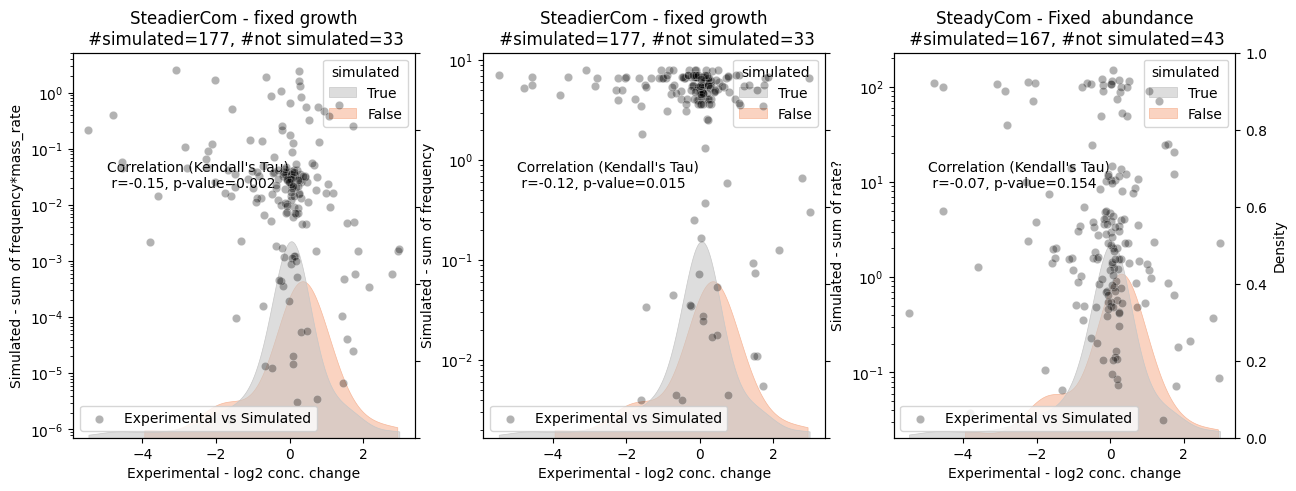

In [12]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(best_predictor.head(3), 
                                        simulation_dict,
                                        signal_exp,
                                        member_or_met=None)


### Best predictors of donor-met relationship

In [13]:

receiver_or_donor = "donor"
mask = (results_corr_df.index.get_level_values("role")==receiver_or_donor)
best_predictor = results_corr_df[mask].sort_values('r',ascending=False)
best_predictor


r  \
role  simulation_method condition                              agg_method metric                          
donor steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.088199   
                                                                          frequency            0.081549   
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.061556   
                        SteadyCom - Nothing fixed              sum        rate?                0.061556   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate  0.027506   
                                                                          frequency           -0.014950   
      smetana           Smetana                                sum        mus                 -1.000000   

                                                                                                p-value  \
role  simulation_method condition                              agg_method metric                          
donor steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate  0.280215   
                                                                          frequency            0.320149   
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                0.565710   
                        SteadyCom - Nothing fixed              sum        rate?                0.565710   
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate  0.744037   
                                                                          frequency            0.859415   
      smetana           Smetana                                sum        mus                  1.000000   

                                                                                               datapoints  
role  simulation_method condition                              agg_method metric                           
donor steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate        70.0  
                                                                          frequency                  70.0  
      steadycom         SteadyCom - Fixed  abundance           sum        rate?                      42.0  
                        SteadyCom - Nothing fixed              sum        rate?                      42.0  
      steadiercom       SteadierCom - fixed growth & abundance sum        frequency*mass_rate        66.0  
                                                                          frequency                  66.0  
      smetana           Smetana                                sum        mus                         2.0

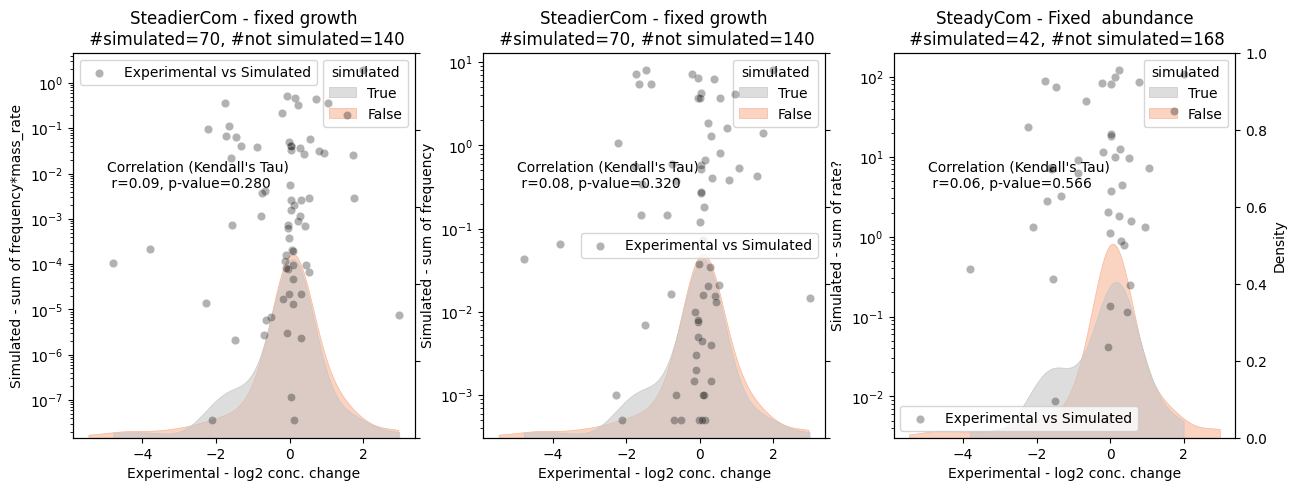

In [14]:
fig,axs,axs_twin = correlation.plot_scatterplots_from_corr(best_predictor.head(3), 
                                        simulation_dict,
                                        signal_exp,
                                        member_or_met=None)



### Correlation by member/metabolite

In [15]:
mask = ((results_corr_member_df["p-value"]<=0.05) 
        & (results_corr_member_df.index.get_level_values("role")=="receiver"))
results_corr_member_df_red = results_corr_member_df[mask].sort_values("r")
results_corr_member_df_red

r  \
role     simulation_method condition                    agg_method metric member             
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA     -0.644444   
                           SteadyCom - Nothing fixed    sum        rate?  CA     -0.644444   
                           SteadyCom - Fixed  abundance sum        rate?  PC      0.555556   
                           SteadyCom - Nothing fixed    sum        rate?  PC      0.555556   

                                                                                   p-value  \
role     simulation_method condition                    agg_method metric member             
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA      0.009148   
                           SteadyCom - Nothing fixed    sum        rate?  CA      0.009148   
                           SteadyCom - Fixed  abundance sum        rate?  PC      0.044615   
                           SteadyCom - Nothing fixed    sum        rate?  PC      0.044615   

                                                                                  datapoints  \
role     simulation_method condition                    agg_method metric member               
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA            10.0   
                           SteadyCom - Nothing fixed    sum        rate?  CA            10.0   
                           SteadyCom - Fixed  abundance sum        rate?  PC             9.0   
                           SteadyCom - Nothing fixed    sum        rate?  PC             9.0   

                                                                                  p-value corrected  \
role     simulation_method condition                    agg_method metric member                      
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA               0.109782   
                           SteadyCom - Nothing fixed    sum        rate?  CA               0.109782   
                           SteadyCom - Fixed  abundance sum        rate?  PC               0.535384   
                           SteadyCom - Nothing fixed    sum        rate?  PC               0.535384   

                                                                                  number comparisons  
role     simulation_method condition                    agg_method metric member                      
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA                      12  
                           SteadyCom - Nothing fixed    sum        rate?  CA                      12  
                           SteadyCom - Fixed  abundance sum        rate?  PC                      12  
                           SteadyCom - Nothing fixed    sum        rate?  PC                      12

#### Best predictor of each member in receiver-metabolite predictors

In [16]:
mask = ~results_corr_member_df_red.index.get_level_values('member').duplicated(keep='first')
best_predicted_members = results_corr_member_df_red[mask]
best_predicted_members


r  \
role     simulation_method condition                    agg_method metric member             
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA     -0.644444   
                                                                          PC      0.555556   

                                                                                   p-value  \
role     simulation_method condition                    agg_method metric member             
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA      0.009148   
                                                                          PC      0.044615   

                                                                                  datapoints  \
role     simulation_method condition                    agg_method metric member               
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA            10.0   
                                                                          PC             9.0   

                                                                                  p-value corrected  \
role     simulation_method condition                    agg_method metric member                      
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA               0.109782   
                                                                          PC               0.535384   

                                                                                  number comparisons  
role     simulation_method condition                    agg_method metric member                      
receiver steadycom         SteadyCom - Fixed  abundance sum        rate?  CA                      12  
                                                                          PC                      12

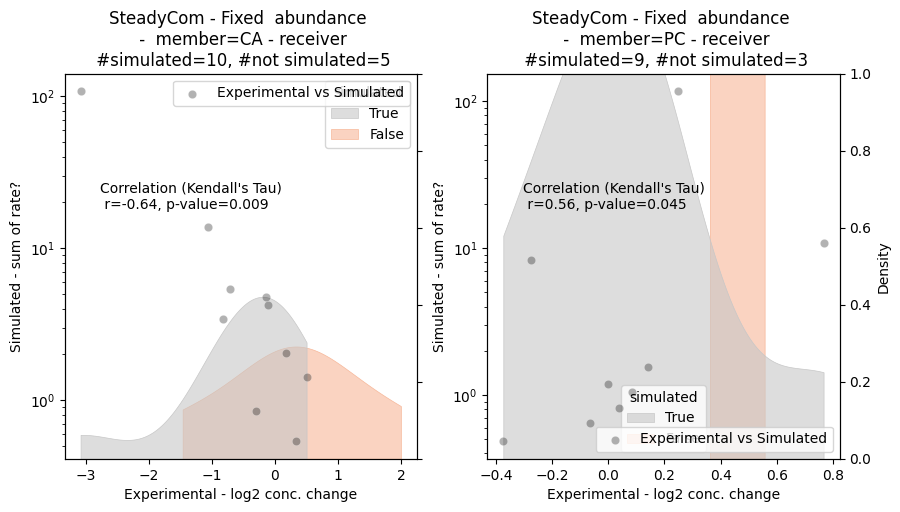

In [17]:
_,_,_ = correlation.plot_scatterplots_from_corr(best_predicted_members, simulation_dict,signal_exp,member_or_met="member",met_column="met_group")


In [18]:
mask = ((results_corr_met_df["p-value"]<=0.05) 
        & (results_corr_met_df.index.get_level_values("role")=="receiver"))
results_corr_met_df_red = results_corr_met_df[mask].sort_values("r")
results_corr_met_df_red

r  \
role     simulation_method condition                              agg_method metric              met_group                   
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool -0.928571   
                           SteadyCom - Nothing fixed              sum        rate?               Tryptophan pool -0.928571   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool    -0.866667   
                                                                                                 Valine pool     -0.511111   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool  0.866667   

                                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric              met_group                   
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool  0.000397   
                           SteadyCom - Nothing fixed              sum        rate?               Tryptophan pool  0.000397   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool     0.016667   
                                                                                                 Valine pool      0.046623   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool  0.016667   

                                                                                                                  datapoints  \
role     simulation_method condition                              agg_method metric              met_group                     
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool         8.0   
                           SteadyCom - Nothing fixed              sum        rate?               Tryptophan pool         8.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool            6.0   
                                                                                                 Valine pool            10.0   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool         6.0   

                                                                                                                  p-value corrected  \
role     simulation_method condition                              agg_method metric              met_group                            
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool           0.013889   
                           SteadyCom - Nothing fixed              sum        rate?               Tryptophan pool           0.013889   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool              0.583333   
                                                                                                 Valine pool               1.631790   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool           0.583333   

                                                                                                                  number comparisons  
role     simulation_method condition                              agg_method metric              met_group                            
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool                  35  
                           SteadyCom - Nothing fixed              sum        rate?               Tryptophan

In [19]:
mask = ~results_corr_met_df_red.index.get_level_values('met_group').duplicated(keep='first')
best_predicted_mets = results_corr_met_df_red[mask]
best_predicted_mets

r  \
role     simulation_method condition                              agg_method metric              met_group                   
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool -0.928571   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool    -0.866667   
                                                                                                 Valine pool     -0.511111   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool  0.866667   

                                                                                                                   p-value  \
role     simulation_method condition                              agg_method metric              met_group                   
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool  0.000397   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool     0.016667   
                                                                                                 Valine pool      0.046623   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool  0.016667   

                                                                                                                  datapoints  \
role     simulation_method condition                              agg_method metric              met_group                     
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool         8.0   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool            6.0   
                                                                                                 Valine pool            10.0   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool         6.0   

                                                                                                                  p-value corrected  \
role     simulation_method condition                              agg_method metric              met_group                            
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool           0.013889   
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool              0.583333   
                                                                                                 Valine pool               1.631790   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool           0.583333   

                                                                                                                  number comparisons  
role     simulation_method condition                              agg_method metric              met_group                            
receiver steadycom         SteadyCom - Fixed  abundance           sum        rate?               Tryptophan pool                  35  
         steadiercom       SteadierCom - fixed growth             sum        frequency*mass_rate Uridine pool                     35  
                                                                                                 Valine pool                      35  
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate Isoleucine pool                  35

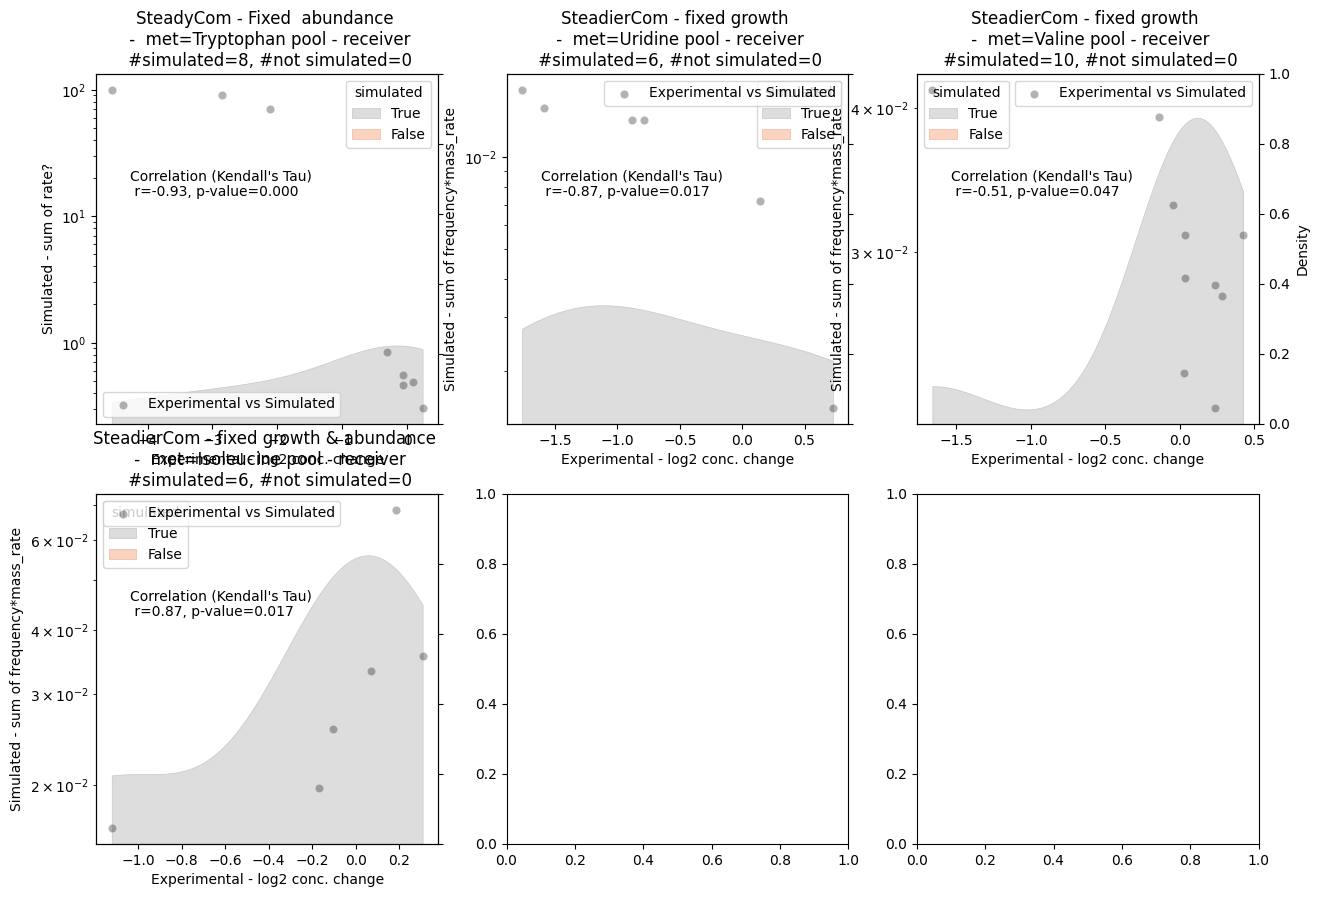

In [20]:
_,_,_ = correlation.plot_scatterplots_from_corr(best_predicted_mets, simulation_dict,signal_exp,member_or_met="met",met_column="met_group")


###  SteadierCom results - frequency

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


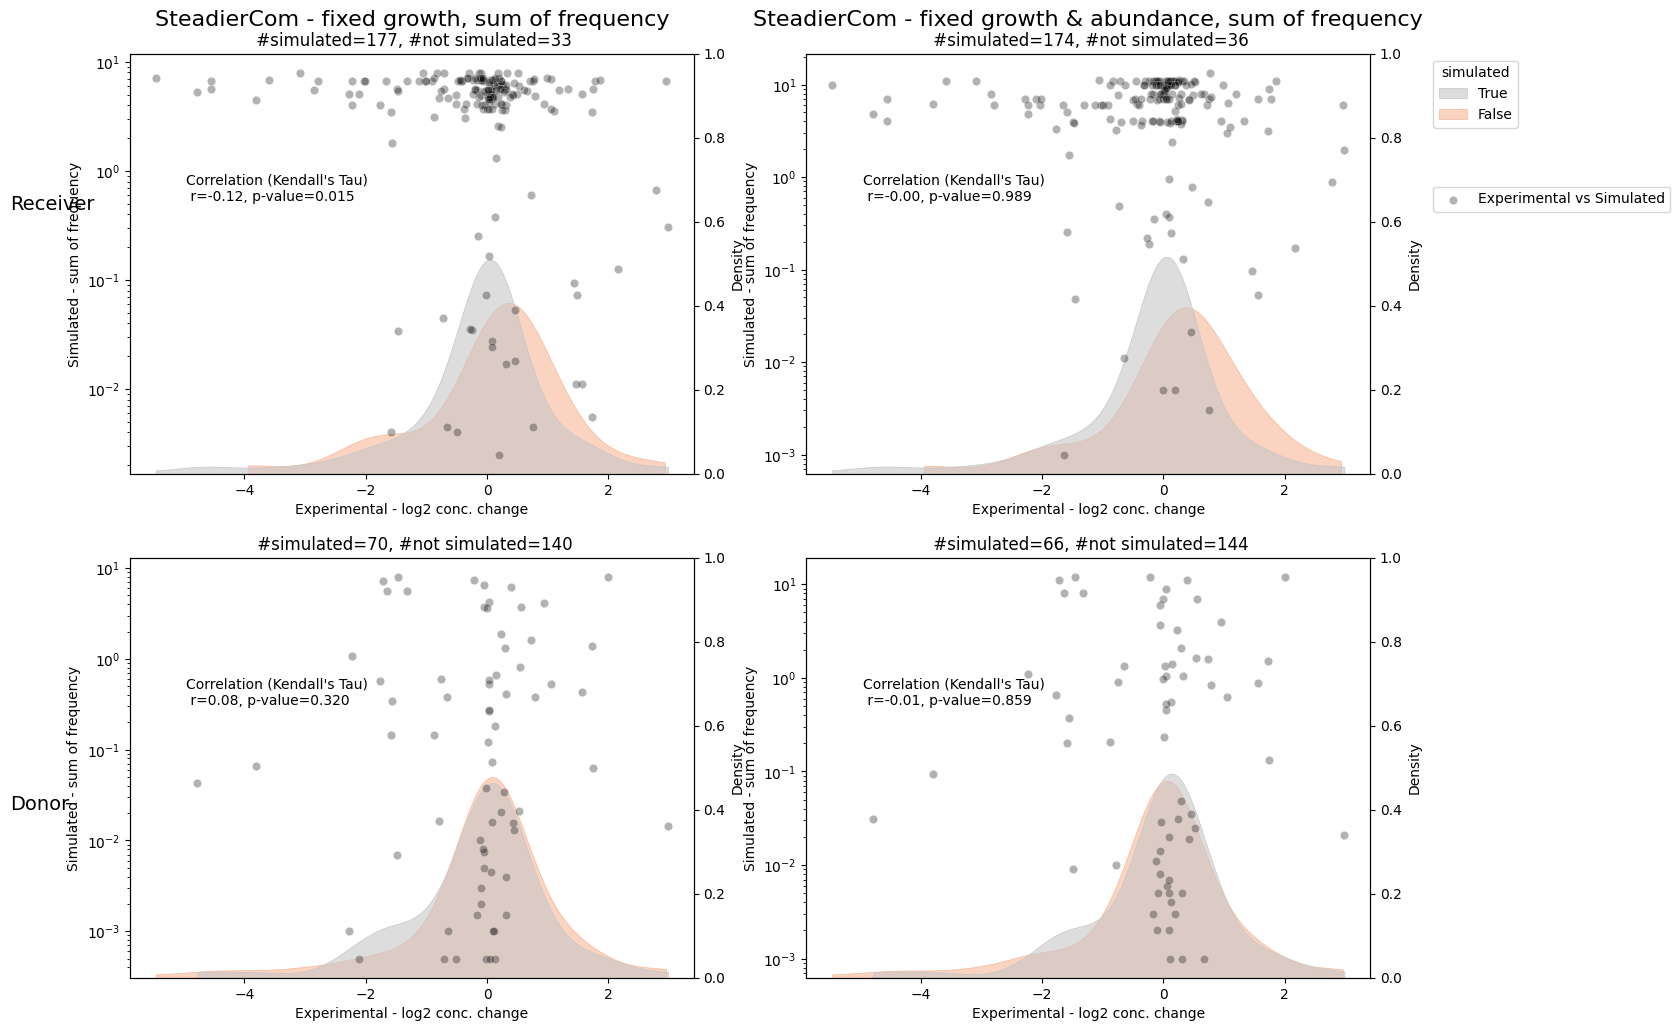

In [21]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="frequency",
                                                )

# Diagnostic analysis - Binary data

In [22]:
support_df = diagnostic.identify_support(signal_exp)
support_df.sort_index(ascending=False)

positive_support  negative_support  total  no-skill line
receiver 1.00                34               176    210       0.161905
         0.50                47               163    210       0.223810
         0.25                59               151    210       0.280952
donor    1.00                22               188    210       0.104762
         0.50                42               168    210       0.200000
         0.25                65               145    210       0.309524

## Precision-Recall curves

In [23]:
results_pr_auc_df = diagnostic.find_pvalues_of_PR(simulation_dict,signal_exp)

INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | merge_sim_exp removes compounds not in experimental data


### Best predictor of receiver-metabolite relationships

In [24]:
mask_best = ((results_pr_auc_df.p_value<0.05) & (results_pr_auc_df.index.get_level_values("role")=="receiver"))

best_pr_predictors = results_pr_auc_df[mask_best].sort_values(by="p_value")
best_pr_predictors


p_value
role     simulation_method condition                  agg_method metric              exp_thresh         
receiver steadiercom       SteadierCom - fixed growth sum        frequency*mass_rate 0.5          0.0067
                                                                                     1.0          0.0201
                                                                 frequency           0.5          0.0403

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


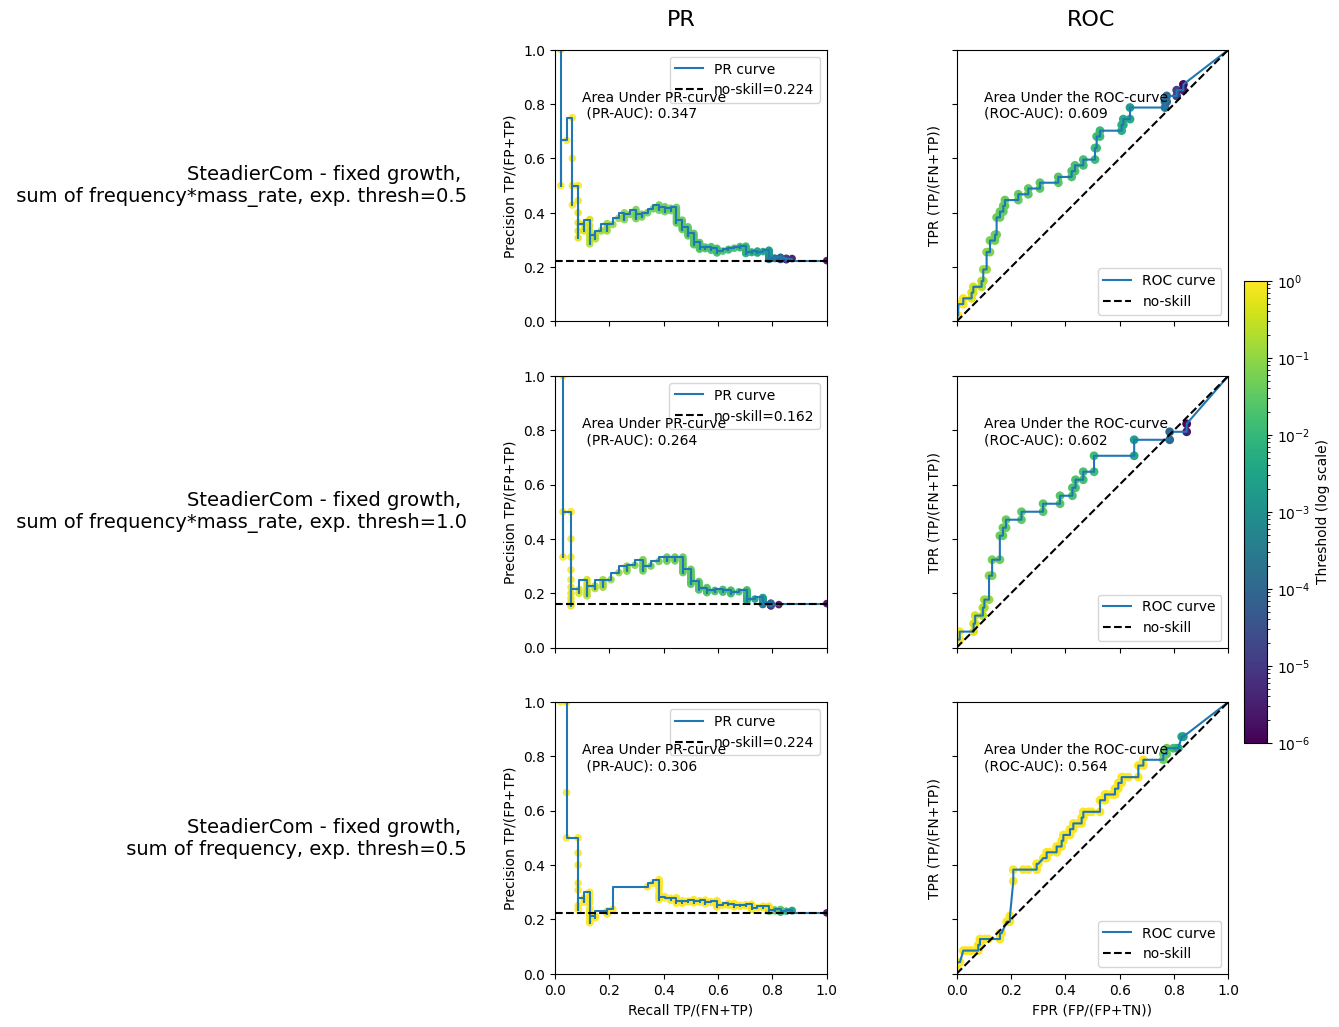

In [25]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(3),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="receiver")

### Best predictor of donor-metabolite relationships

In [26]:
mask_best = ((results_pr_auc_df.p_value<0.05) & (results_pr_auc_df.index.get_level_values("role")=="donor"))

best_pr_predictors = results_pr_auc_df[mask_best].sort_values(by="p_value")
best_pr_predictors


,,,,,,p_value
role,simulation_method,condition,agg_method,metric,exp_thresh,
donor,steadiercom,SteadierCom - fixed growth & abundance,sum,frequency*mass_rate,1.0,0.049


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


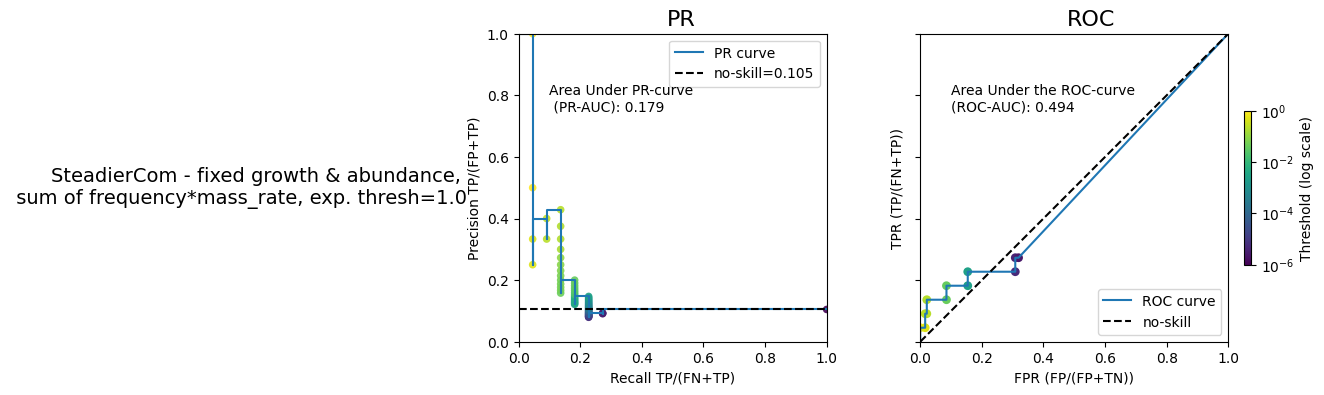

In [27]:
fig, axs = diagnostic.plot_diagnostic_curves_pvalues(best_pr_predictors.head(3),
                                                  simulation_dict,
                                                  signal_exp,
                                                  receiver_or_donor="donor")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


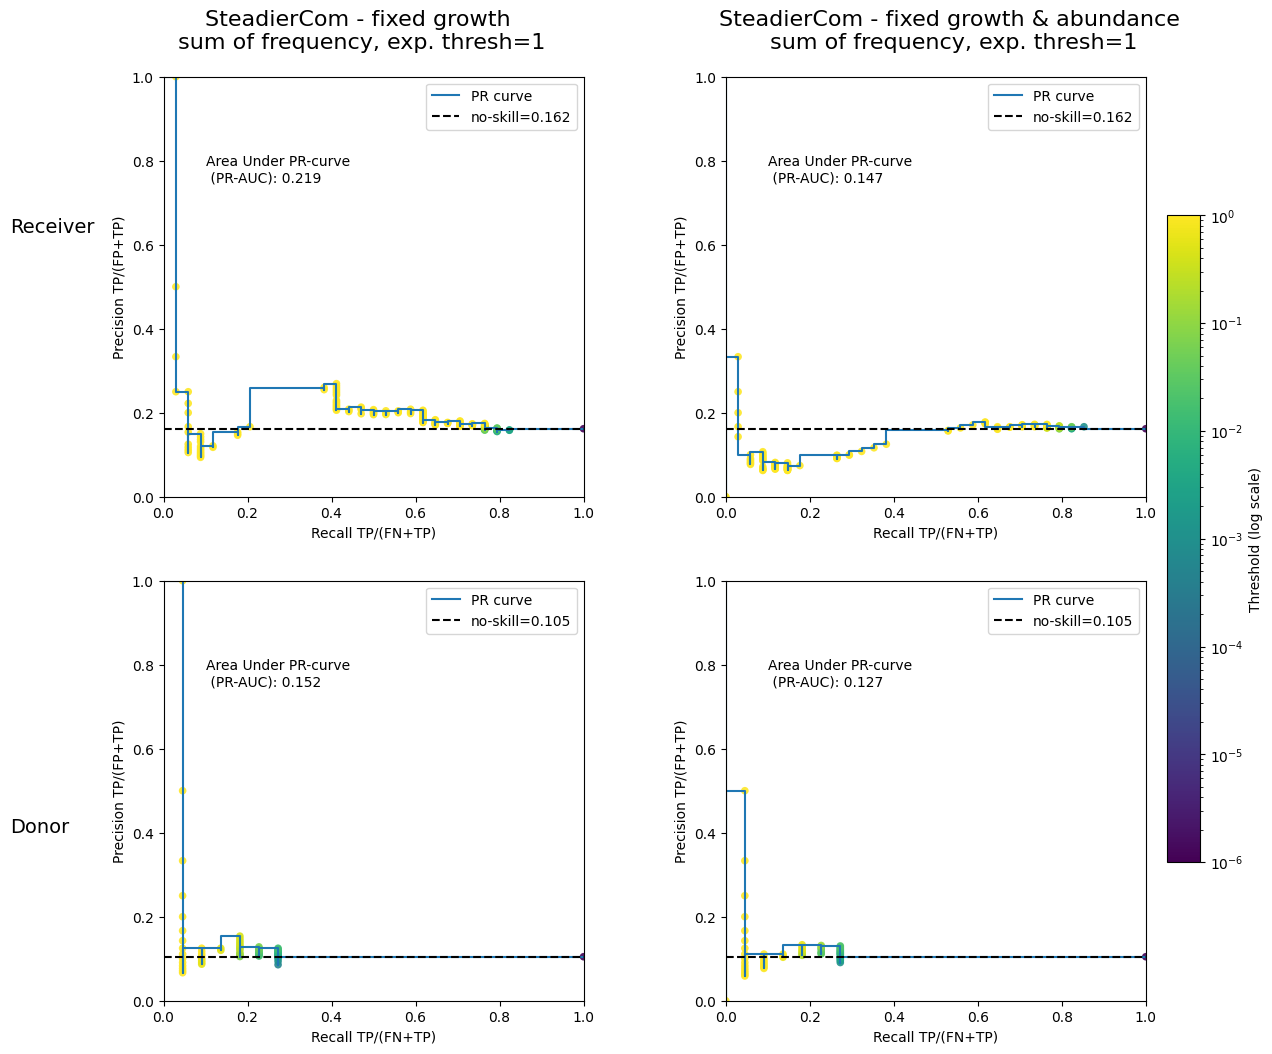

In [28]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


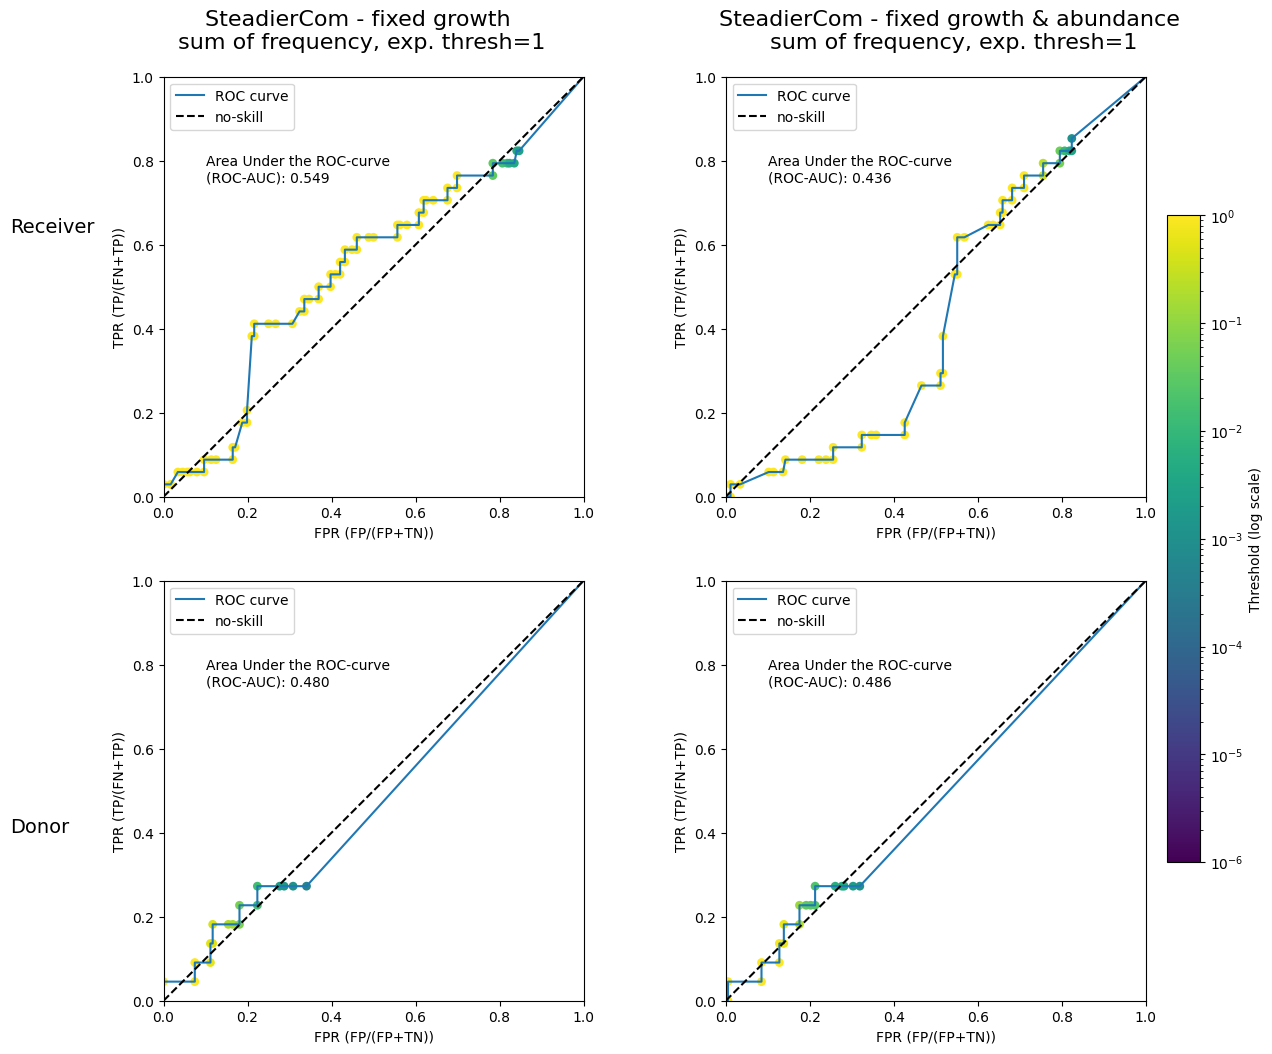

In [29]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    PR_or_ROC="ROC",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


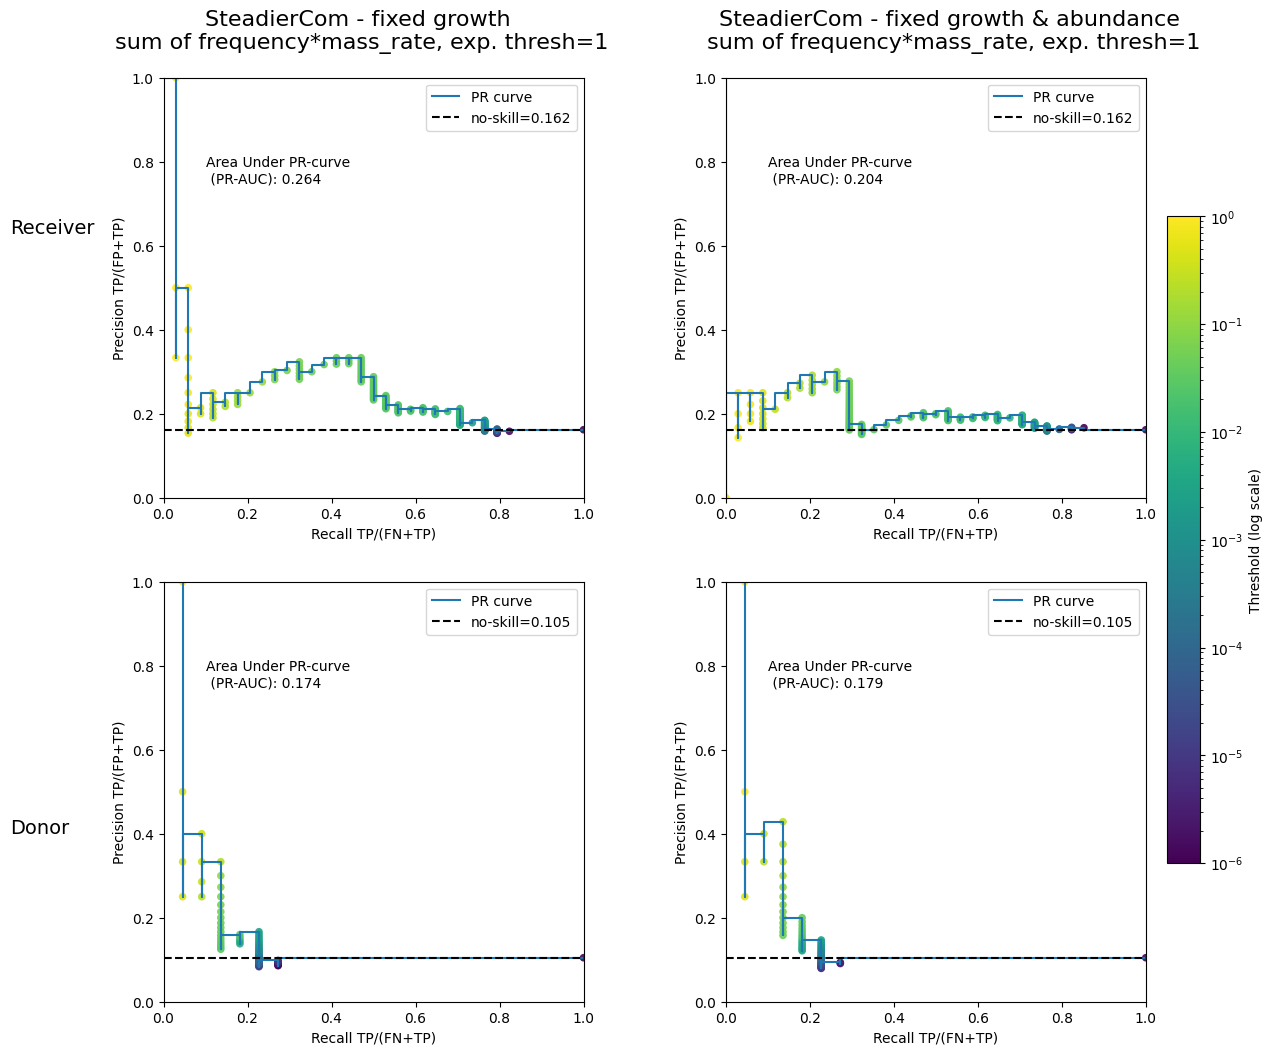

In [30]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes compounds not in experimental data


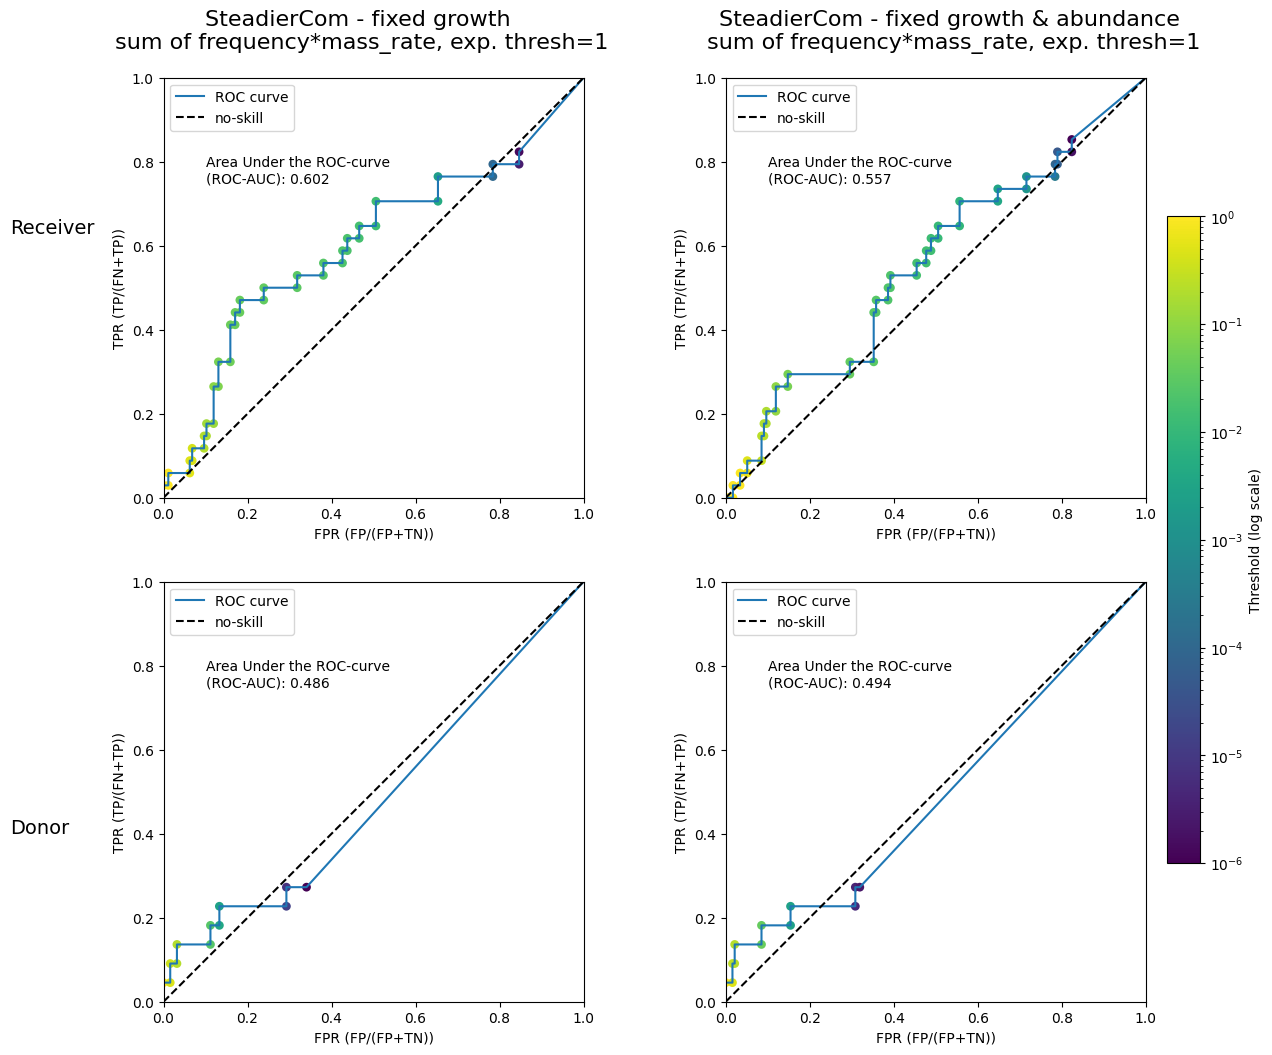

In [31]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency*mass_rate",
                                                    PR_or_ROC="ROC",
                                                    met_column="met_group",
                                                    agg_method="sum")